# FMCG Global Demand Planning and Forecasting — Capstone

## TL;DR
This project analyses 1,100,000 recorded sales rows from 2021–2023 for 102 SKUs in seven countries. It covers cleaning, SQL retrieval, ABC/XYZ segmentation, promotion and price analysis, geographic demand, chronological SKU demand forecasting, and stockout classification. Histogram Gradient Boosting yielded lower mean per-SKU error than Linear Regression in a one-step-ahead backtest, but the stockout classifier has very low precision; neither result proves actual inventory savings.

**Source:** `fmcg_raw_data.zip` (FMCG CSV only). **Dataset caveat:** the supplied data does not contain the 15 countries or 350+ SKUs described in the guide. All financial units retain source-defined, unspecified currency.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
REPORTS = ROOT / 'reports'
assert (REPORTS / 'data_audit.json').exists(), 'Run scripts/pipeline.py first'
def read_json(name):
    return json.loads((REPORTS / name).read_text())
def figure(name):
    display(Image(filename=str(REPORTS / 'figures' / name)))

## 1. Data preparation & SQL retrieval
The SQL queries in `sql/analysis_queries.sql` demonstrate filtering, grain validation, grouping and aggregation. A `store_id` key is needed to avoid false duplicates: multiple stores can share the same city, channel, SKU, and date.

In [2]:
audit = read_json('data_audit.json')
display(pd.Series(audit, name='value').to_frame())
assert audit['duplicate_store_sku_day'] == 0
assert audit['missing_cells'] == 0

,value
rows,1100000
columns,33
date_start,2021-01-01
date_end,2023-12-31
countries,7
cities,9
stores,13
skus,102
channels,"{'Hypermarket': 525600, 'Supermarket': 262800,..."
missing_cells,0


## 2. Exploratory data analysis and market dynamics
Inspect the time series, geography, revenue concentration, weekly variability, and store-level logistics patterns. The dataset has only 13 stores, so geographical analysis is indicative rather than a high-resolution logistics-desert assessment.

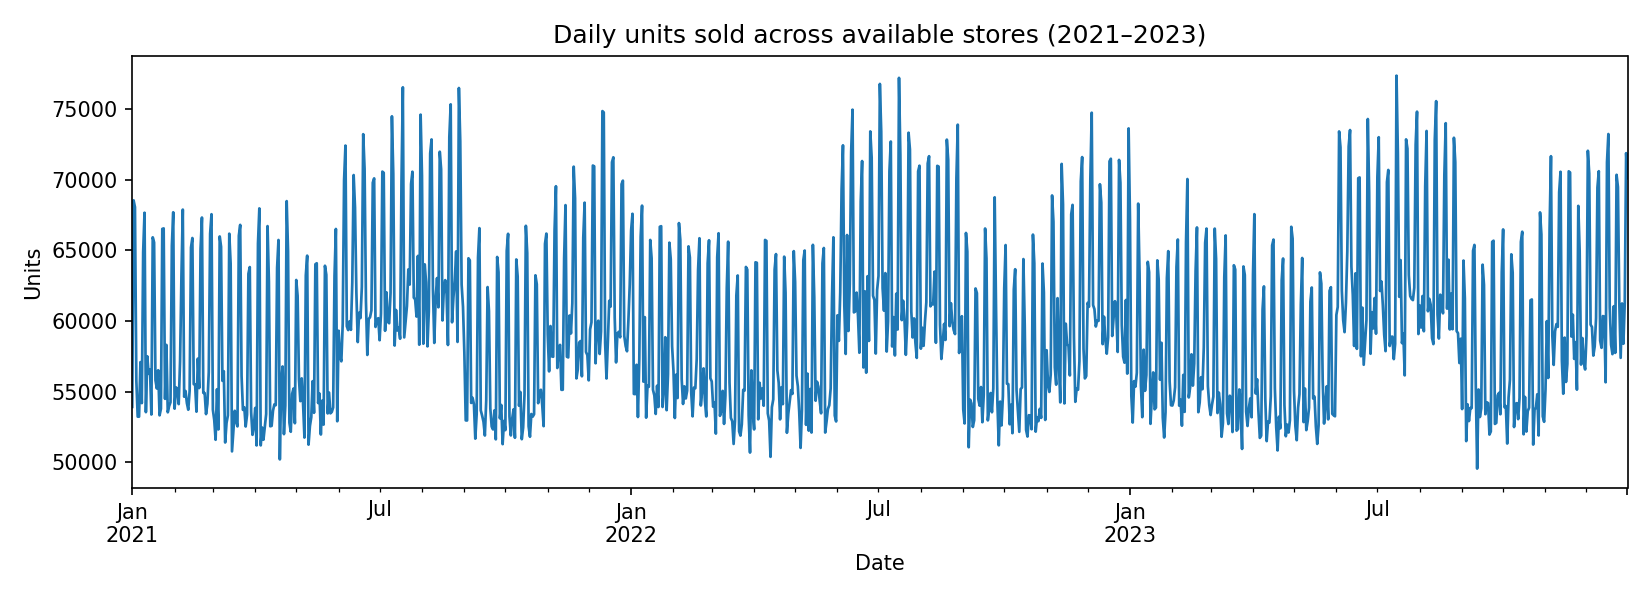

In [3]:
figure('daily_sales.png')

,country,units,revenue,stockout_rate,mean_lead_time
0,Italy,19361774,1.371931e+08,0.030,6.497
1,Spain,14668017,1.067048e+08,0.030,6.501
2,Germany,11738571,8.852556e+07,0.030,6.505
3,Austria,5742174,4.302003e+07,0.031,6.494
4,France,6014974,4.260161e+07,0.031,6.500
5,Poland,5860180,4.238526e+07,0.030,6.506
6,Netherlands,1730292,1.251615e+07,0.030,6.508


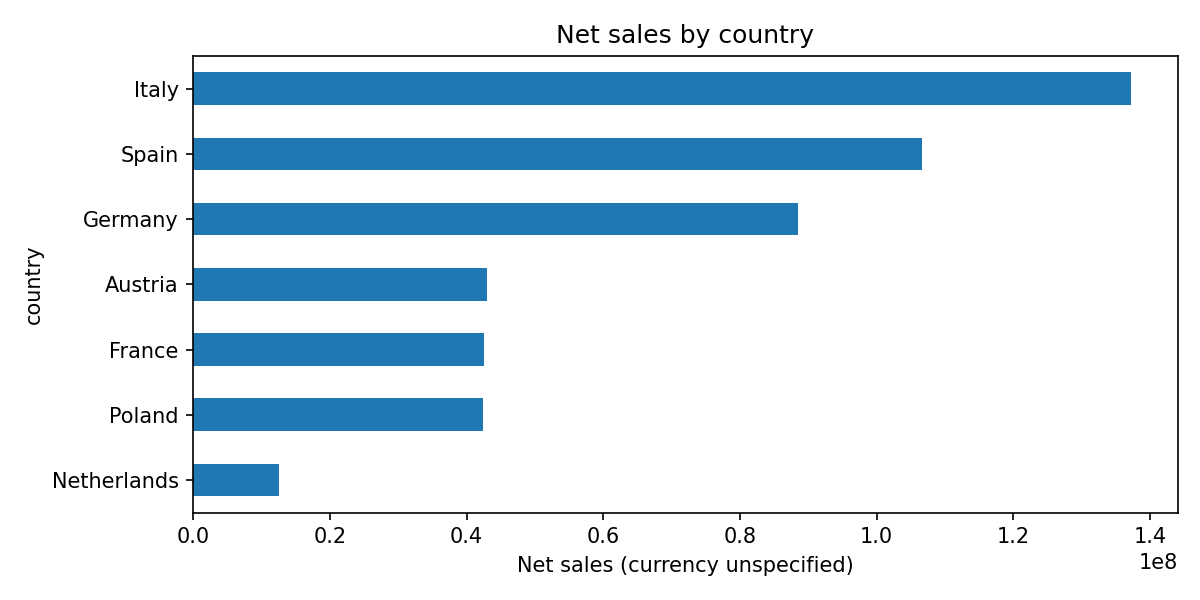

In [4]:
regions = pd.read_csv(REPORTS/'country_metrics.csv')
display(regions.round(3))
figure('country_revenue.png')

,sku_id,revenue,cv,ABC,XYZ,segment
0,SKU0018,17032424.64,0.202,A,X,AX
1,SKU0027,16000295.02,0.148,A,X,AX
2,SKU0026,13025419.73,0.120,A,X,AX
3,SKU0099,12968809.43,0.144,A,X,AX
4,SKU0092,12496995.90,0.062,A,X,AX
5,SKU0100,12351150.68,0.056,A,X,AX
6,SKU0064,12326994.00,0.062,A,X,AX
7,SKU0061,11967260.40,0.059,A,X,AX
8,SKU0028,11749108.59,0.122,A,X,AX
9,SKU0097,11594508.71,0.056,A,X,AX


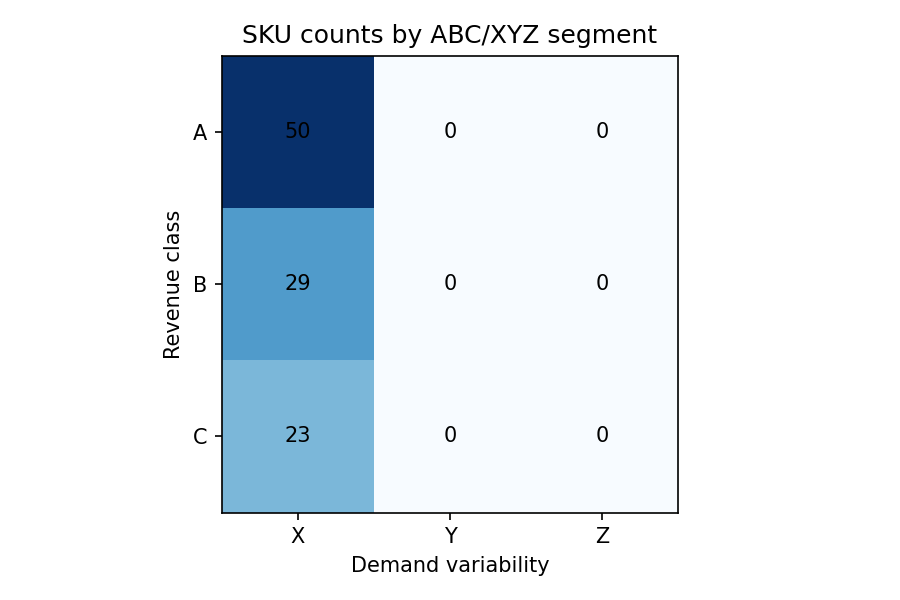

In [5]:
segments = pd.read_csv(REPORTS/'sku_segmentation.csv')
display(segments[['sku_id','revenue','cv','ABC','XYZ','segment']].head(12).round(3))
figure('abc_xyz.png')

,country,city,store_id,latitude,longitude,mean_lead,lead_sd,stockout_rate,units
0,Austria,Vienna,STORE0008,48.203,16.359,6.494,2.008,0.031,5742174
12,Spain,Madrid,STORE0012,40.417,-3.675,6.512,2.019,0.031,5243338
1,France,Paris,STORE0006,48.876,2.360,6.500,2.016,0.031,6014974
6,Italy,Rome,STORE0002,41.940,12.506,6.499,2.012,0.031,4249838
8,Netherlands,Amsterdam,STORE0013,52.362,4.958,6.508,2.032,0.030,1730292
7,Italy,Rome,STORE0011,41.908,12.513,6.497,2.014,0.030,5985522
2,Germany,Berlin,STORE0001,52.526,13.391,6.506,2.009,0.030,5681442
3,Germany,Berlin,STORE0004,52.501,13.421,6.505,2.014,0.030,6057129


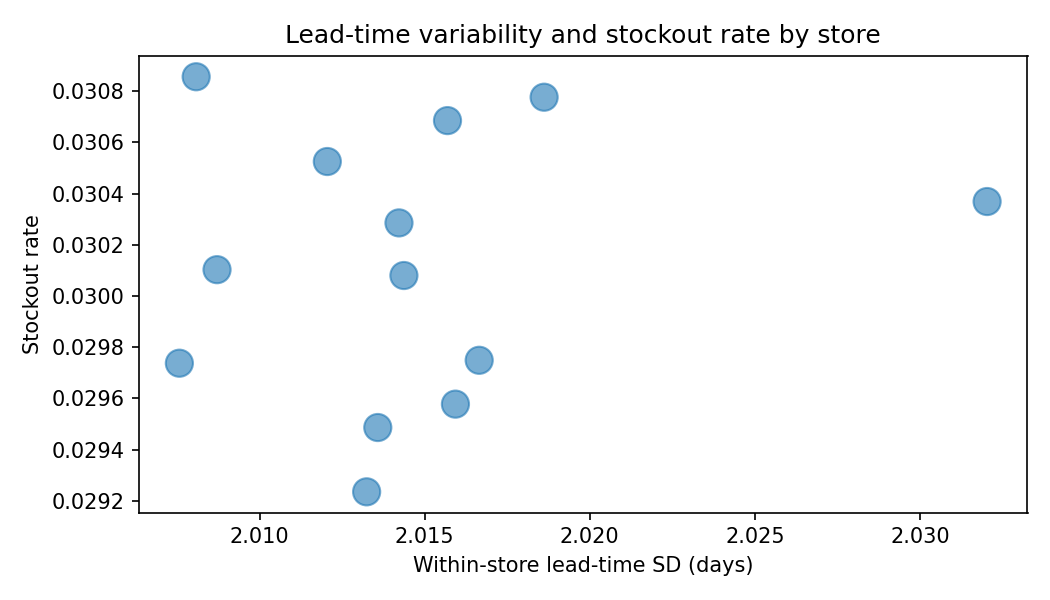

In [6]:
logistics = pd.read_csv(REPORTS/'logistics_store_metrics.csv')
display(logistics.sort_values('stockout_rate',ascending=False).head(8).round(3))
figure('logistics_risk.png')

## 3. Hypothesis testing and price elasticity
**Null hypothesis:** promotional transactions and non-promotional transactions have equal mean units. Welch’s two-sample test measures a difference in recorded mean sales, **not causal promotional lift**. Promotions may be allocated to high-volume stores or seasonal periods; transactions are clustered and not independently randomized. A separate price regression includes SKU, month and weekday fixed effects, but remains observational.

In [7]:
promo = read_json('promotion_test.json')
price = read_json('price_association.json')
display(pd.Series(promo, name='promotion analysis').to_frame())
display(pd.Series(price, name='price association').to_frame())

,promotion analysis
mean_units_promo,104.267582
mean_units_nonpromo,55.264665
relative_difference_pct,88.669527
welch_t_statistic,195.042611
p_value,0.0
interpretation,Observational association only; promotions may...


,price association
log_price_coefficient,-0.789796
log_price_ci95,"[-0.9005696524613301, -0.6790218605782198]"
p_value,0.0
sample_size,120000
method,"OLS, log(1+units) ~ log(discount-adjusted pric..."
caution,Associational approximate elasticity only; sto...


## 4. Feature engineering and leakage-safe preprocessing

SKU-level daily demand forecasting uses lagged sales at 1, 7 and 30 days, a shifted 7-day moving average, weekday/month/weekend/holiday/month-boundary flags, recorded promotional share, price, rainfall and temperature. Linear Regression uses a `StandardScaler` fitted on its training window **only**, whereas tree boosting does not require scaling. SKU-level aggregation makes SKU, store and country categories constant or undefined for this forecast; the stockout model separately uses one-hot categorical encoding at store–SKU grain.

**Prediction contract:** this is a one-step-ahead historical backtest with actual lagged history and contemporaneous price/weather/promotion inputs; it is not a standalone 184-day future forecast. Same-day variables require external forecasts or planned promotion/price inputs in live use.


In [8]:
from pathlib import Path
import json
notes = json.loads((REPORTS/'preprocessing_and_stockout_notes.json').read_text())
print('Forecast features: lag 1/7/30; shifted rolling 7; weekday, month, weekend, holiday, month start/end; promotion, price and weather.')
print('Linear Regression: training-only fitted StandardScaler; Gradient Boosting: raw numerical features.')
print('Stockout classification: training-only StandardScaler + OneHotEncoder; categories:', notes['categorical_features'])
print('Chronological split:', notes['train_period'], '| Test:', notes['test_period'])


Forecast features: lag 1/7/30; shifted rolling 7; weekday, month, weekend, holiday, month start/end; promotion, price and weather.
Linear Regression: training-only fitted StandardScaler; Gradient Boosting: raw numerical features.
Stockout classification: training-only StandardScaler + OneHotEncoder; categories: ['sku_id', 'store_id', 'channel', 'country']
Chronological split: 2021-01-01 through 2023-06-30 (after available lags) | Test: 2023-07-01 through 2023-12-31


## 5. Machine learning forecasting
We compare Linear Regression with Histogram Gradient Boosting for 10 revenue/volatility-diverse SKUs. ADF stationarity tests are diagnostics; differencing is not automatically applied to the tree model, because doing so can obscure demand levels. Model accuracy is measured in original demand units using MAE, RMSE, non-zero-denominator MAPE, and WAPE.

,sku_id,segment,model,train_rows,test_rows,MAE,RMSE,MAPE_pct_nonzero,WAPE_pct
0,SKU0018,AX,Linear Regression,881,184,100.96,126.13,9.57,9.24
1,SKU0018,AX,Histogram Gradient Boosting,881,184,90.33,113.74,8.84,8.27
2,SKU0027,AX,Linear Regression,881,184,134.51,183.65,12.04,11.51
3,SKU0027,AX,Histogram Gradient Boosting,881,184,125.00,174.83,10.79,10.70
4,SKU0010,BX,Linear Regression,881,184,54.84,73.69,12.88,12.59
5,SKU0010,BX,Histogram Gradient Boosting,881,184,46.07,62.83,10.65,10.58
6,SKU0022,CX,Linear Regression,881,184,99.06,134.59,10.54,10.28
7,SKU0022,CX,Histogram Gradient Boosting,881,184,92.99,128.70,10.03,9.65
8,SKU0026,AX,Linear Regression,881,184,89.66,114.18,10.66,10.53
9,SKU0026,AX,Histogram Gradient Boosting,881,184,84.67,108.50,10.19,9.94


,model,MAE,RMSE,MAPE_pct_nonzero,WAPE_pct
0,Histogram Gradient Boosting,85.75,111.97,9.74,9.47
1,Linear Regression,87.75,113.27,10.05,9.76


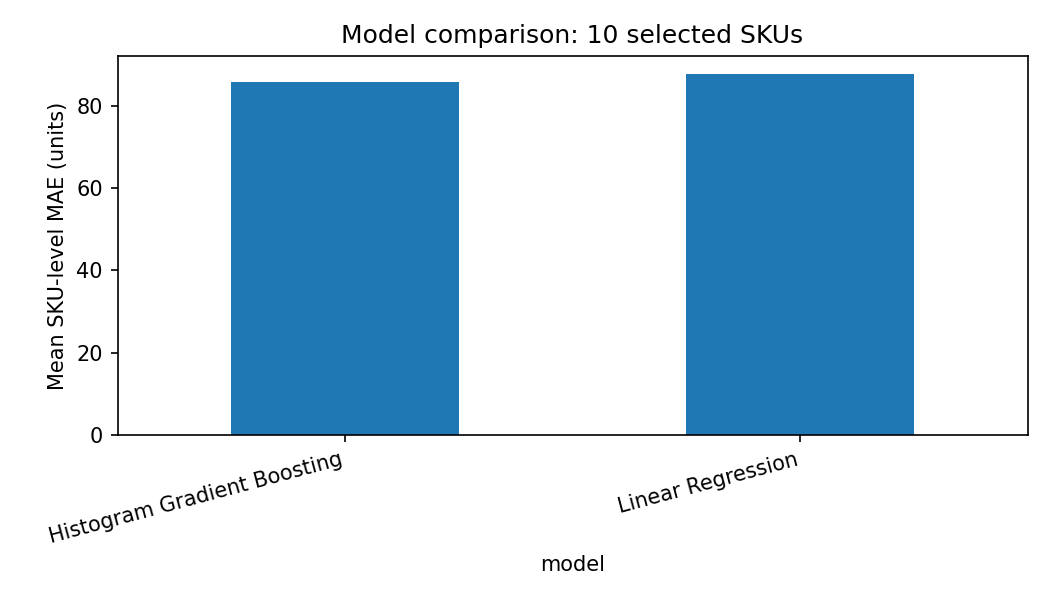

In [9]:
metrics = pd.read_csv(REPORTS/'model_metrics.csv')
summary = pd.read_csv(REPORTS/'model_comparison.csv')
display(metrics.round(2))
display(summary.round(2))
figure('model_comparison.png')

,sku_id,adf_statistic,p_value,stationary_at_005
0,SKU0018,-2.2240,0.1977,False
1,SKU0027,-5.8302,0.0000,True
2,SKU0010,-3.1130,0.0256,True
3,SKU0022,-2.4491,0.1284,False
4,SKU0026,-2.7766,0.0617,False
5,SKU0099,-27.8817,0.0000,True
6,SKU0092,-5.7784,0.0000,True
7,SKU0100,-6.5590,0.0000,True
8,SKU0064,-6.7575,0.0000,True
9,SKU0061,-7.7695,0.0000,True


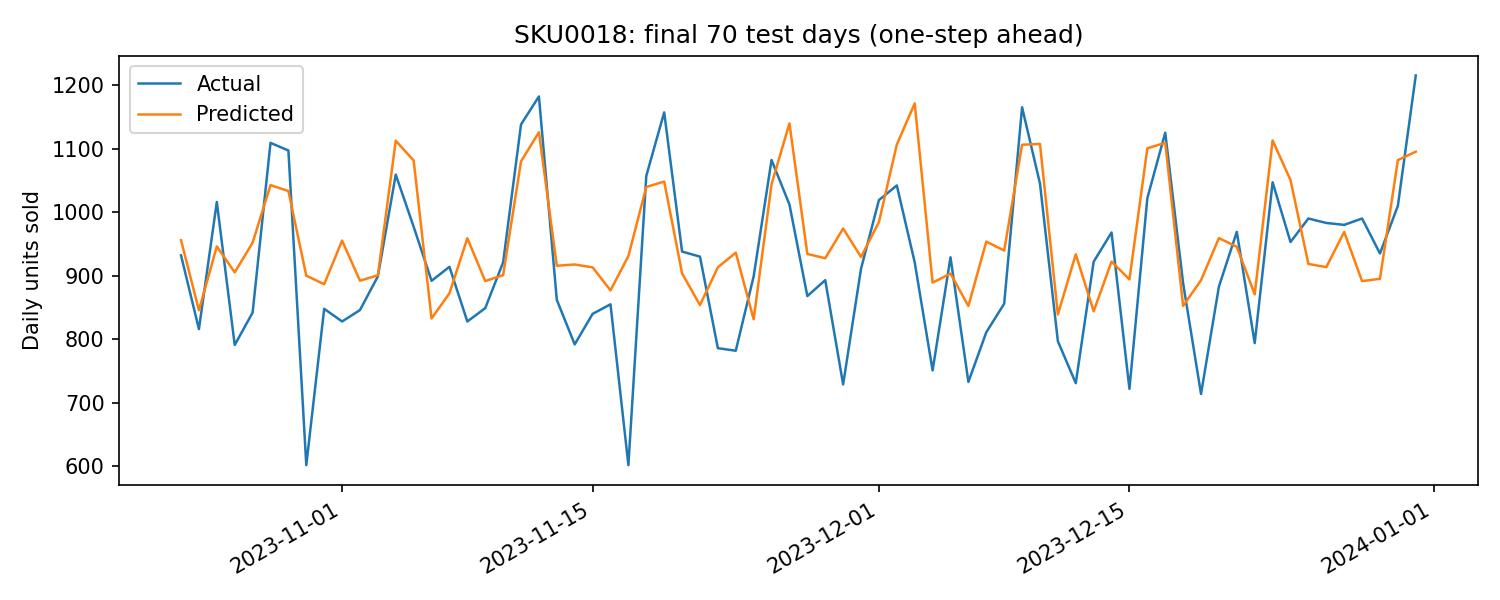

In [10]:
stationarity = pd.read_csv(REPORTS/'adf_stationarity.csv')
display(stationarity.round(4))
figure('forecast_example.png')

## 6. Explainability, fairness and business recommendations
Permutation importance illustrates what raises error when shuffled for **one representative SKU**, not a universal ranking. Review measured stockout rates by channel, but note that this dataset labels its channels Hypermarket, Supermarket, Convenience and E-commerce: a dedicated “Traditional Trade” category is missing.

,feature,mae_increase
0,rolling_7,84.90
1,day_of_week,51.36
2,month,33.51
3,lag_1,27.02
4,lag_7,2.77
5,temperature,1.79
6,rain_mm,1.10
7,lag_30,0.93
8,is_month_end,0.52
9,is_weekend,0.00


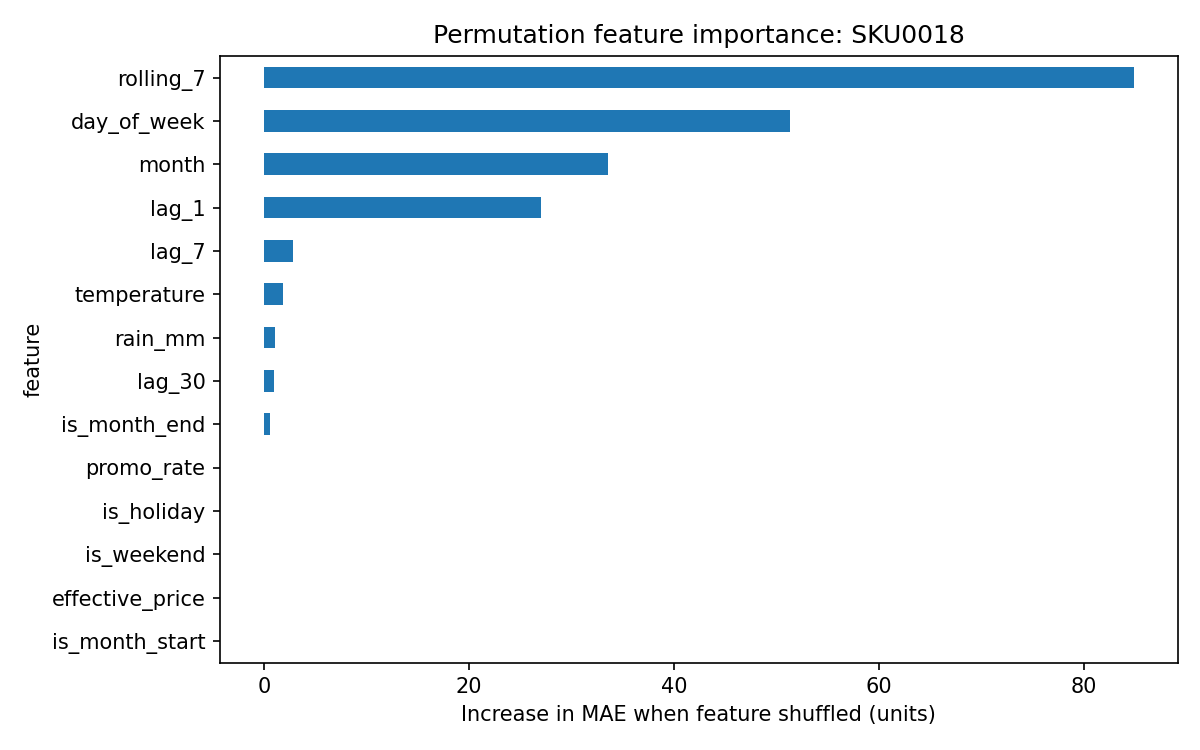

,channel,records,stockout_rate,units,lead_time,promo_share
0,Convenience,48800,0.0304,1730292,6.5076,0.0898
1,E-commerce,262800,0.0301,15647980,6.5011,0.0808
2,Hypermarket,525600,0.0303,35341421,6.5013,0.0800
3,Supermarket,262800,0.0297,12396289,6.4966,0.0783


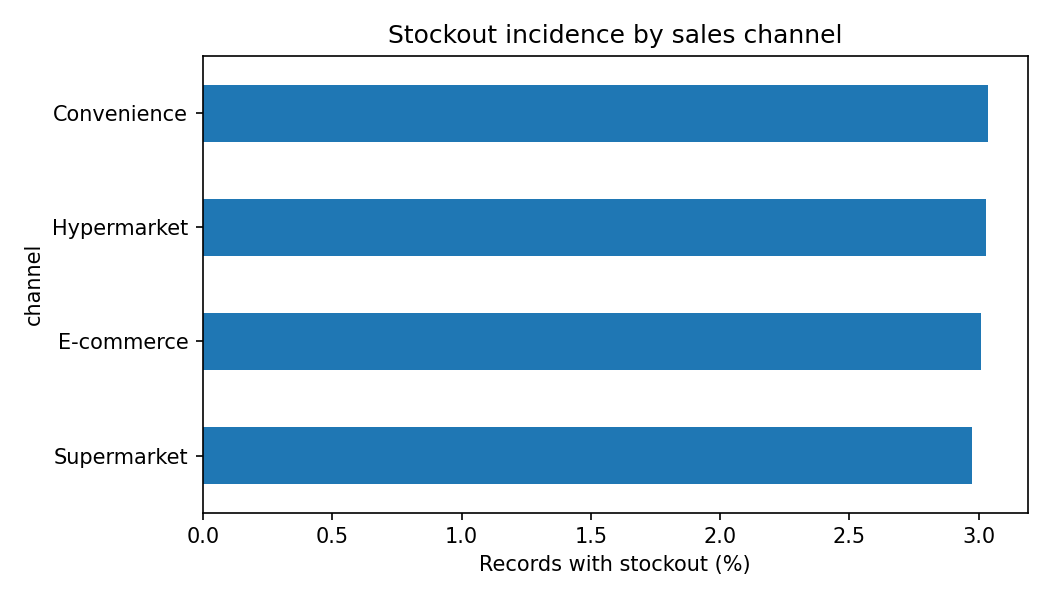

In [11]:
importance = pd.read_csv(REPORTS/'feature_importance_example.csv')
equity = pd.read_csv(REPORTS/'channel_equity.csv')
display(importance.round(2))
figure('feature_importance.png')
display(equity.round(4))
figure('channel_stockout.png')

## 7. Geospatial analysis and logistics hotspots

The plotted locations are **13 geocoded stores** across nine cities, with bubble area/color proportional to recorded sold units. A store is marked as a potential *logistics hotspot* only if it is at or above the 75th percentile for both sales volume and within-store lead-time standard deviation. This is a relative exploratory flag, not a validated measure of warehouse accessibility or a literal map of deserts.

,country,city,store_id,units_sold,lead_time_sd,stockout_rate
3,Germany,Berlin,STORE0004,6057129,2.014372,0.030080
1,France,Paris,STORE0006,6014974,2.015692,0.030685
7,Italy,Rome,STORE0011,5985522,2.014223,0.030285
9,Poland,Warsaw,STORE0005,5860180,2.015932,0.029578
0,Austria,Vienna,STORE0008,5742174,2.008080,0.030856
2,Germany,Berlin,STORE0001,5681442,2.008712,0.030103
11,Spain,Barcelona,STORE0009,5297695,2.016652,0.029749
12,Spain,Madrid,STORE0012,5243338,2.018619,0.030776
5,Italy,Milan,STORE0010,5106947,2.007571,0.029737
6,Italy,Rome,STORE0002,4249838,2.012052,0.030525


Relative high-demand/high-variability hotspot stores: 1


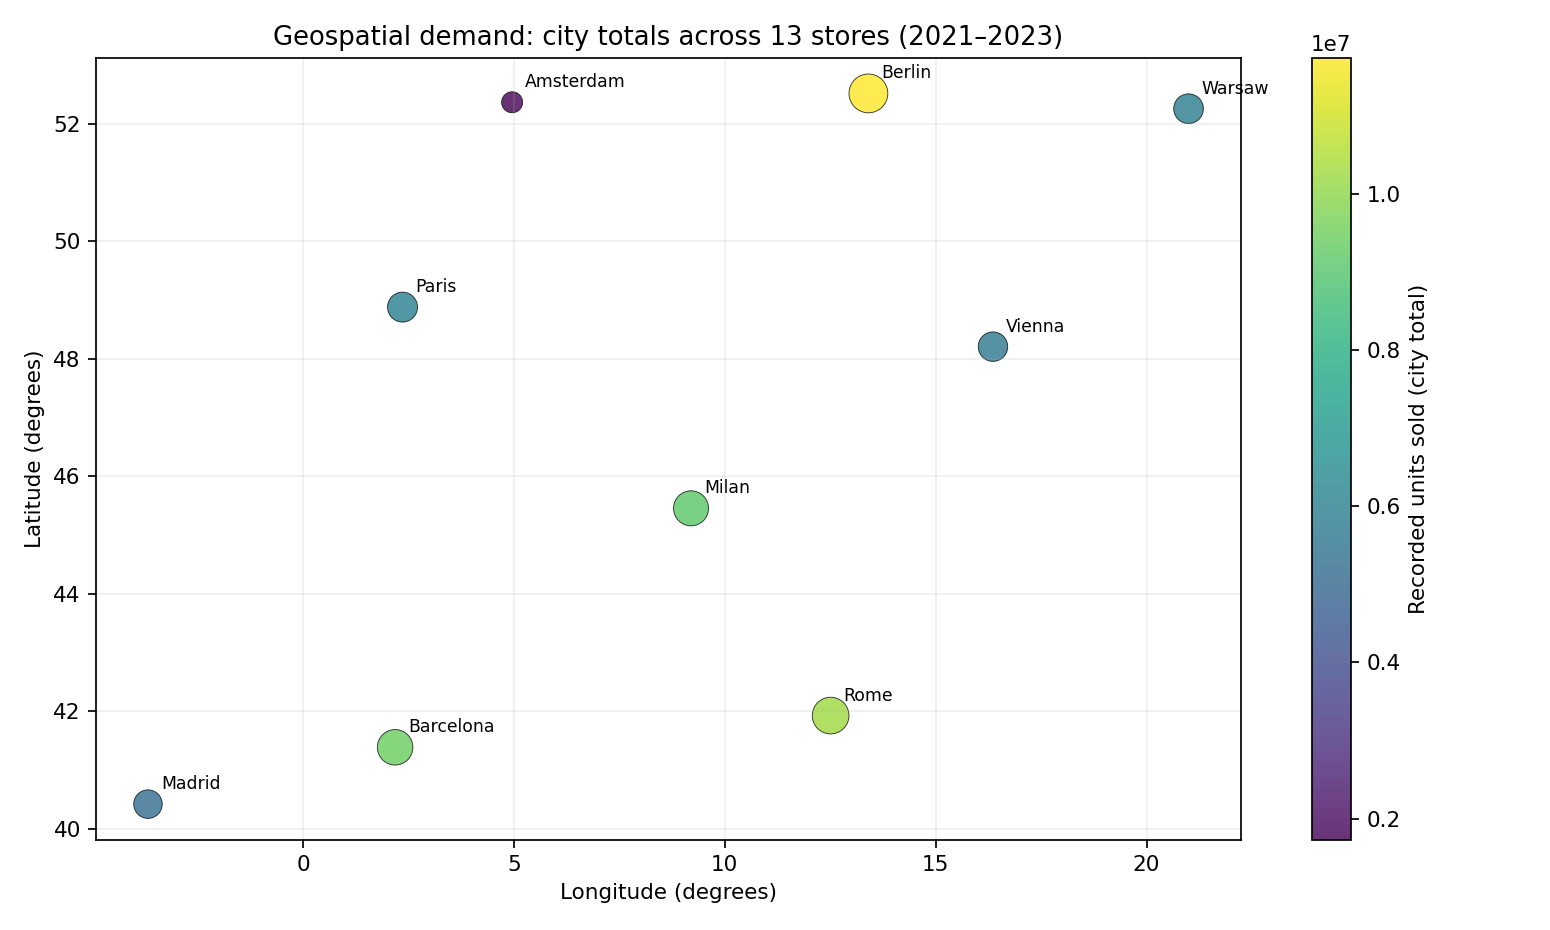

In [12]:
geo = pd.read_csv(REPORTS/'geospatial_sales_density.csv')
hotspots = pd.read_csv(REPORTS/'geospatial_logistics_hotspots.csv')
display(geo[['country','city','store_id','units_sold','lead_time_sd','stockout_rate']].sort_values('units_sold',ascending=False).head(10))
print('Relative high-demand/high-variability hotspot stores:', int(hotspots.logistics_hotspot.sum()))
figure('geospatial_demand.png')

## 8. Stockout prediction and responsible interpretation

The target is `stock_out_flag` at store–SKU–recorded-date grain. Lagged units and lagged stockout flags use **prior observations only**, never current inventory or same-day outcomes. Preprocessing uses `StandardScaler` on numerical features and `OneHotEncoder(handle_unknown="ignore")` on SKU/store/channel/country; all transformations are fitted on chronological training observations only. A reproducible subset of at most 230,000 training rows controls compute; the entire July–December 2023 test period is retained.

A fixed 0.50 threshold and balanced Logistic Regression are evaluated against an all-negative baseline. Very low precision is an important warning about false alerts in an imbalanced dataset. These metrics should not be interpreted as operational stock savings. Channel-specific recall/precision are screening diagnostics, not proof of fair allocation.

,model,test_rows,test_prevalence,precision,recall,f1,predicted_positive_rate
0,Always predict no stockout,184736,0.0298,0.0000,0.0000,0.0000,0.0000
1,Logistic Regression (threshold 0.50),184736,0.0298,0.0297,0.5059,0.0561,0.5065


,channel,records,stockout_rate,recall,precision
0,Convenience,8096.0,0.0294,0.5924,0.0287
1,E-commerce,44160.0,0.0302,0.4655,0.0291
2,Hypermarket,88320.0,0.0305,0.5372,0.0311
3,Supermarket,44160.0,0.0280,0.4648,0.0276


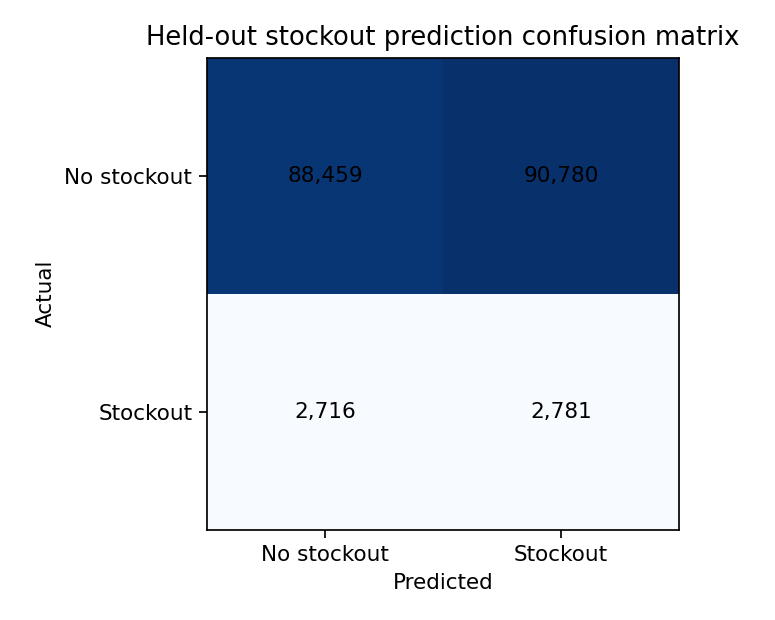

Average precision (PR-AUC): 0.0293


In [13]:
classification = pd.read_csv(REPORTS/'stockout_classification_metrics.csv')
channel_fairness = pd.read_csv(REPORTS/'stockout_channel_fairness.csv')
display(classification.round(4))
display(channel_fairness.round(4))
figure('stockout_confusion_matrix.png')
print('Average precision (PR-AUC):', round(notes['average_precision'],4))

## 9. Takeaways and limitations

1. Use the measured per-SKU backtest error to prioritize products for improved replenishment decisions; the results do not prove lower realized stockouts or inventory costs.
2. Apply ABC/XYZ-specific review cadences and safety-stock planning **only after validating lead-time demand and actual desired service levels**. The data contains lead times and stockout flags but does not establish a replenishment policy.
3. Promotions correlate with higher unit sales, but the observational Welch test does not establish incremental causal demand.
4. Check channel-level stockout disparity in deployment; don't systematically disadvantage small retailers. The supplied data cannot directly identify “Traditional Trade”.
5. **Deployment gap:** The current evaluation uses actual same-day prices, promotions and weather and actual lagged unit sales during the test period. For forecasts beyond one day, supply a promotion calendar, price plan, weather scenario and recursive/iterative predictions, then evaluate that separate realistic horizon.
6. **Data gaps:** only 7 countries, 9 cities, 13 stores and 102 SKUs versus the larger scope in the guide; stockouts may censor true demand. The source currency is not specified; revenue figures should not be assigned an assumed currency.

**Presentation storyline:** problem → data audit → ABC/XYZ / regional patterns → promotional test → 10-SKU forecasting → feature importance / channel equity → inventory-management next steps.


The extra geospatial assessment covers 13 stores, not a representative global geography. The stockout classifier was run but **does not have sufficient precision for deployment**; future work should improve labels, use operationally available predictors, tune alert thresholds on a validation period, and assess net alert cost.
